In [1]:
%pip install pandas numpy scikit-learn matplotlib seaborn torch joblib

  Using cached torch-2.15.0-cp314-cp314-win_amd64.whl.metadata (36 kB)
Using cached torch-2.15.0-cp314-cp314-win_amd64.whl (126.7 MB)
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, GlobalAveragePooling1D,
    Dense, Dropout, BatchNormalization
)
from tensorflow.keras.callbacks import EarlyStopping

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

os.makedirs("outputs", exist_ok=True)

print("Libraries imported successfully")

Libraries imported successfully


In [5]:
import os

print("Current folder:", os.getcwd())
print("Files in this folder:", os.listdir())

Current folder: C:\Users\Admin\outputs
Files in this folder: ['.ipynb_checkpoints', 'champion_model.joblib', 'confusion_matrix.png', 'model_comparison.csv', 'model_tuning_results.csv', 'outputs', 'roc_auc_comparison.png', 'spam_text_classifier.ipynb']


In [7]:
import urllib.request
import zipfile
import os

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

zip_path = "spam_dataset.zip"

urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("spam_dataset")

print("Dataset downloaded successfully!")
print(os.listdir("spam_dataset"))

Dataset downloaded successfully!
['readme', 'SMSSpamCollection']


In [8]:
import pandas as pd

df = pd.read_csv(
    "spam_dataset/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print(df.head())
print("Dataset shape:", df.shape)

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Dataset shape: (5572, 2)


In [9]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " URL ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_message"] = df["message"].apply(clean_text)

df = df[df["clean_message"].str.len() > 0]

print(df.head())

  label                                            message  \
0   ham  Go until jurong point, crazy.. Available only ...   
1   ham                      Ok lar... Joking wif u oni...   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...   
3   ham  U dun say so early hor... U c already then say...   
4   ham  Nah I don't think he goes to usf, he lives aro...   

                                       clean_message  
0  go until jurong point crazy available only in ...  
1                            ok lar joking wif u oni  
2  free entry in 2 a wkly comp to win fa cup fina...  
3        u dun say so early hor u c already then say  
4  nah i don t think he goes to usf he lives arou...  


In [10]:
df["target"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

print(df["target"].value_counts())

target
0    4823
1     747
Name: count, dtype: int64


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["clean_message"],
    df["target"],
    test_size=0.20,
    random_state=42,
    stratify=df["target"]
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4456
Testing samples: 1114


In [12]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 10000
MAX_LENGTH = 100

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

vocab_size = min(
    MAX_WORDS,
    len(tokenizer.word_index) + 1
)

print("Vocabulary size:", vocab_size)
print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)

Vocabulary size: 7706
Training shape: (4456, 100)
Testing shape: (1114, 100)


In [14]:
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.Input(shape=(MAX_LENGTH,)),

    tf.keras.layers.Embedding(
        input_dim=vocab_size,
        output_dim=64
    ),

    tf.keras.layers.GlobalAveragePooling1D(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.4),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │       493,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 510,337 (1.95 MB)

 Trainable params: 510,081 (1.95 MB)

 Non-trainable params: 256 (1.00 KB)

In [15]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.20,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.9026 - loss: 0.2938 - val_accuracy: 0.8419 - val_loss: 0.5830
Epoch 2/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9868 - loss: 0.0432 - val_accuracy: 0.8419 - val_loss: 0.6286
Epoch 3/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9966 - loss: 0.0133 - val_accuracy: 0.8419 - val_loss: 0.6517
Epoch 4/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9986 - loss: 0.0055 - val_accuracy: 0.8643 - val_loss: 0.5410
Epoch 5/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9997 - loss: 0.0019 - val_accuracy: 0.9686 - val_loss: 0.1076
Epoch 6/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9994 - loss: 0.0022 - val_accuracy: 0.9843 - val_loss: 0.0672
Epoch 7/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9978 - loss: 0.0078 - val_accuracy: 0.7567 - val_loss: 0.6257
Epoch 8/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 1.0000 - loss: 0.0012 - val_accu

In [ ]:
import matplotlib.pyplot as plt
import os

os.makedirs("outputs", exist_ok=True)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()

plt.savefig("outputs/training_curves.png", dpi=300)

plt.show()

In [17]:
test_loss, test_accuracy = model.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))
print("Test Accuracy (%):", round(test_accuracy * 100, 2))

Test Loss: 0.0683
Test Accuracy: 0.9856
Test Accuracy (%): 98.56


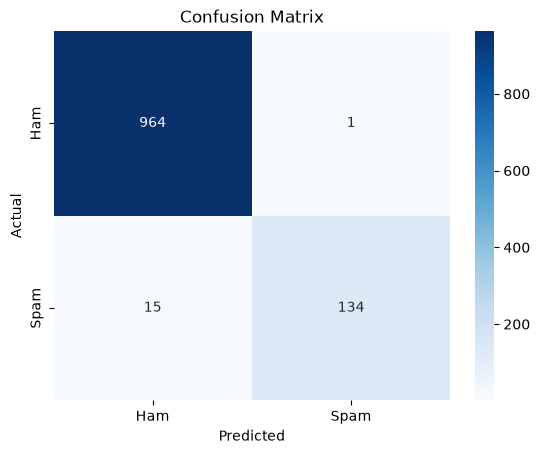

              precision    recall  f1-score   support

         Ham     0.9847    0.9990    0.9918       965
        Spam     0.9926    0.8993    0.9437       149

    accuracy                         0.9856      1114
   macro avg     0.9886    0.9491    0.9677      1114
weighted avg     0.9857    0.9856    0.9853      1114



In [18]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_prob = model.predict(X_test_pad, verbose=0).flatten()
y_pred = (y_prob >= 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.savefig("outputs/confusion_matrix.png", dpi=300)

plt.show()

report = classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"],
    digits=4
)

print(report)

with open("outputs/classification_report.txt", "w") as f:
    f.write(report)

In [19]:
def predict_message(message):
    cleaned = clean_text(message)

    sequence = tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post"
    )

    probability = float(
        model.predict(padded, verbose=0)[0][0]
    )

    label = "Spam" if probability >= 0.5 else "Ham"

    confidence = (
        probability if label == "Spam"
        else 1 - probability
    )

    print("Message:", message)
    print("Prediction:", label)
    print("Confidence:", round(confidence * 100, 2), "%")
    print("-" * 40)

    return {
        "message": message,
        "prediction": label,
        "spam_probability": probability,
        "confidence": confidence
    }

predict_message("Congratulations! You have won a free prize. Call now!")
predict_message("Hi, are we meeting at college tomorrow?")
predict_message("URGENT! Claim your cash reward today.")
predict_message("Please send me the notes for today's lecture.")

Message: Congratulations! You have won a free prize. Call now!
Prediction: Spam
Confidence: 98.41 %
----------------------------------------
Message: Hi, are we meeting at college tomorrow?
Prediction: Ham
Confidence: 100.0 %
----------------------------------------
Message: URGENT! Claim your cash reward today.
Prediction: Ham
Confidence: 58.55 %
----------------------------------------
Message: Please send me the notes for today's lecture.
Prediction: Ham
Confidence: 99.77 %
----------------------------------------


{'message': "Please send me the notes for today's lecture.",
 'prediction': 'Ham',
 'spam_probability': 0.002267142990604043,
 'confidence': 0.997732857009396}

In [20]:
model.save("outputs/spam_classifier.keras")

sample_messages = [
    "Congratulations! You have won a free prize.",
    "Hi, are we meeting at college tomorrow?",
    "Claim your cash reward today.",
    "Please send me the notes."
]

results = [
    predict_message(message)
    for message in sample_messages
]

pd.DataFrame(results).to_csv(
    "outputs/sample_predictions.csv",
    index=False
)

print("Model and predictions saved successfully.")

Message: Congratulations! You have won a free prize.
Prediction: Spam
Confidence: 73.98 %
----------------------------------------
Message: Hi, are we meeting at college tomorrow?
Prediction: Ham
Confidence: 100.0 %
----------------------------------------
Message: Claim your cash reward today.
Prediction: Ham
Confidence: 89.52 %
----------------------------------------
Message: Please send me the notes.
Prediction: Ham
Confidence: 99.93 %
----------------------------------------
Model and predictions saved successfully.


In [21]:
for root, dirs, files in os.walk("outputs"):
    for file in files:
        print(os.path.join(root, file))

outputs\classification_report.txt
outputs\confusion_matrix.png
outputs\sample_predictions.csv
outputs\spam_classifier.keras


Current folder: C:\Users\Admin\outputs
Training history available: True


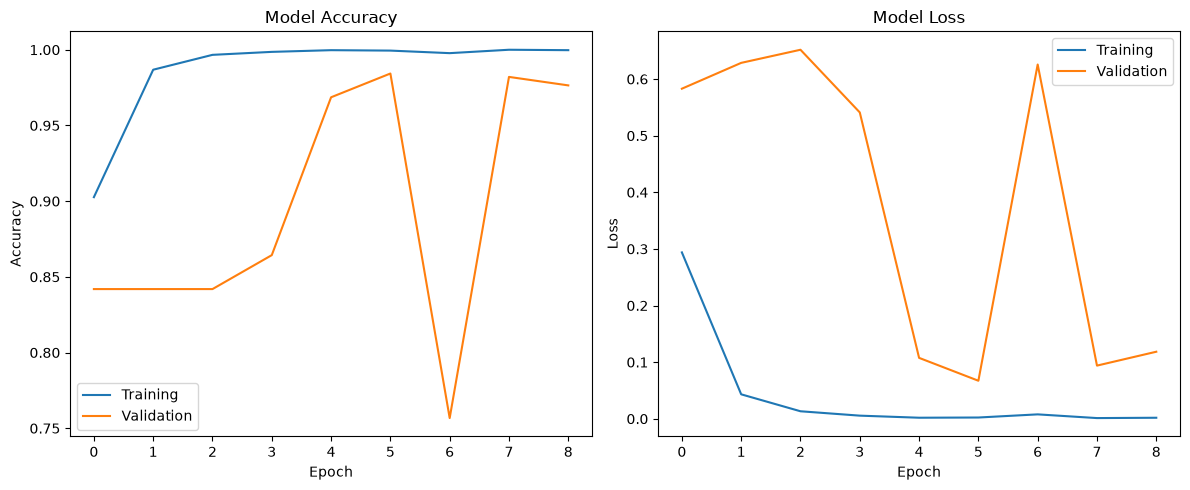

Saved at: C:\Users\Admin\outputs\outputs\training_curves.png


In [24]:
import os
import matplotlib.pyplot as plt

print("Current folder:", os.getcwd())
print("Training history available:", "history" in globals())

if "history" not in globals():
    print("Please run Step 8 (model training) first.")
else:
    os.makedirs("outputs", exist_ok=True)

    plt.figure(figsize=(12, 5))

    # Accuracy graph
    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], label="Training")
    plt.plot(history.history["val_accuracy"], label="Validation")
    plt.title("Model Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    # Loss graph
    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], label="Training")
    plt.plot(history.history["val_loss"], label="Validation")
    plt.title("Model Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()

    plt.savefig(
        "outputs/training_curves.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved at:", os.path.abspath("outputs/training_curves.png"))

In [23]:
for root, dirs, files in os.walk("outputs"):
    for file in files:
        print(os.path.join(root, file))

outputs\classification_report.txt
outputs\confusion_matrix.png
outputs\sample_predictions.csv
outputs\spam_classifier.keras
outputs\training_curves.png


In [25]:
import os

model_path = "outputs/spam_classifier.keras"

print("File exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print("File size:", os.path.getsize(model_path), "bytes")

File exists: True
File size: 6164338 bytes


In [26]:
import tensorflow as tf

loaded_model = tf.keras.models.load_model(
    "outputs/spam_classifier.keras"
)

print("Model loaded successfully!")
loaded_model.summary()

Model loaded successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │       493,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,530,501 (5.84 MB)

 Trainable params: 510,081 (1.95 MB)

 Non-trainable params: 256 (1.00 KB)

 Optimizer params: 1,020,164 (3.89 MB)